<a href="https://colab.research.google.com/github/zouhiraghenaim/Unsupervised---Learning-Algorithms/blob/main/K-Means-Clustering/TP8_01_K_mean_Clustring_model.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


##**K_means Clustering**


***K-Means clustering*** is an unsupervised machine learning algorithm that partitions a dataset
into K distinct, non-overlapping groups by minimizing the distance between data points
and their cluster's center (centroid). The algorithm works iteratively: it assigns each data
point to the nearest centroid, then recalculates the centroids based on the mean of the
assigned points, repeating until the clusters stabilize.


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files

In [ ]:
upload=files.upload()

Saving kmean_cluster.csv to kmean_cluster (1).csv


In [ ]:
df_1=pd.read_csv('kmean_cluster.csv',sep=';')
print(df_1)

  Customer  X_1?Age  X_2: Income (10k)  X_3: Visits/month  X_4 Clicks/visit  \
0        A       20                  3                 10                15   
1        B       25                  4                  8                12   
2        C       50                  9                  2                 3   
3        D       55                 10                  1                 2   
4        E       45                  8                  3                 5   

   X_5: Spend (10)  
0                2  
1                3  
2               10  
3               12  
4                9  


In [ ]:
df_1.describe()

,X_1?Age,X_2: Income (10k),X_3: Visits/month,X_4 Clicks/visit,X_5: Spend (10)
count,5.000000,5.000000,5.000000,5.000000,5.000000
mean,39.000000,6.800000,4.800000,7.400000,7.200000
std,15.572412,3.114482,3.962323,5.770615,4.438468
min,20.000000,3.000000,1.000000,2.000000,2.000000
25%,25.000000,4.000000,2.000000,3.000000,3.000000
50%,45.000000,8.000000,3.000000,5.000000,9.000000
75%,50.000000,9.000000,8.000000,12.000000,10.000000
max,55.000000,10.000000,10.000000,15.000000,12.000000


In [ ]:
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

print("KMeans and StandardScaler packages imported successfully!")

KMeans and StandardScaler packages imported successfully!


**Reasoning**:
Scale the numerical features from df_1 using StandardScaler as specified in the subtask instructions.



In [ ]:
# Extract numerical features by dropping 'Customer' column
numerical_features = df_1.drop(columns=['Customer'])

# Initialize the StandardScaler
scaler = StandardScaler()

# Fit and transform the numerical features
scaled_features = scaler.fit_transform(numerical_features)

# Print the scaled features to confirm correctness
print("Scaled Features Array:\n", scaled_features)

Scaled Features Array:
 [[-1.3641205  -1.3641205   1.46726488  1.47247009 -1.30986108]
 [-1.00514142 -1.00514142  0.90293224  0.8912319  -1.05796472]
 [ 0.78975397  0.78975397 -0.79006571 -0.85248268  0.70530981]
 [ 1.14873305  1.14873305 -1.07223203 -1.04622875  1.20910253]
 [ 0.4307749   0.4307749  -0.50789938 -0.46499055  0.45341345]]


**Reasoning**:
We will calculate the inertia (within-cluster sum of squares) for K values ranging from 1 to 5 (since there are 5 samples) using KMeans with random_state=42 on the scaled features, and plot the Elbow curve to determine the optimal number of clusters.



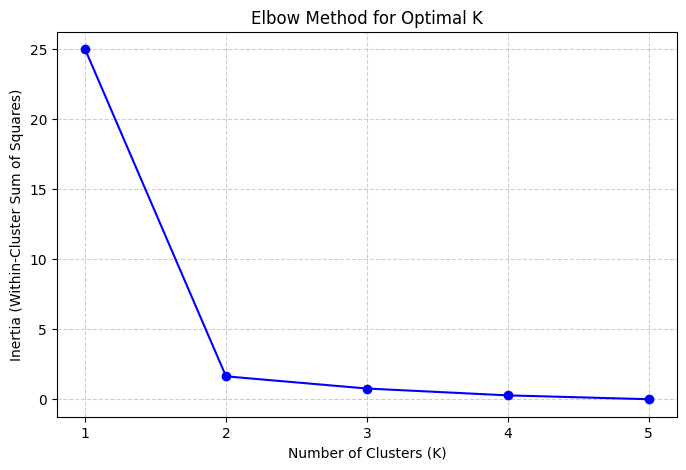

Clusters: 1, Inertia: 25.0000
Clusters: 2, Inertia: 1.6347
Clusters: 3, Inertia: 0.7642
Clusters: 4, Inertia: 0.2755
Clusters: 5, Inertia: 0.0000


In [ ]:
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

# Define the range of clusters (1 to 5, as there are 5 data points)
K_range = range(1, 6)
inertia = []

# Calculate inertia for each K
for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(scaled_features)
    inertia.append(kmeans.inertia_)

# Plot the Elbow Curve
plt.figure(figsize=(8, 5))
plt.plot(K_range, inertia, marker='o', linestyle='-', color='b')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('Inertia (Within-Cluster Sum of Squares)')
plt.title('Elbow Method for Optimal K')
plt.xticks(K_range)
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

# Print the inertia values
for k, val in zip(K_range, inertia):
    print(f"Clusters: {k}, Inertia: {val:.4f}")

### Mathematical Explanation of WCSS (Within-Cluster Sum of Squares)

WCSS is calculated as:
$$\text{WCSS} = \sum_{i \in S_1} ||x_i - \mu_1||^2 + \sum_{j \in S_2} ||x_j - \mu_2||^2 + \dots + \sum_{m \in S_k} ||x_m - \mu_k||^2$$

Where:
* $S_k$ is the set of data points belonging to cluster $k$.
* $\mu_k$ is the centroid of cluster $k$.

Let's run a calculation block to extract and display the exact WCSS values.

In [ ]:
import pandas as pd
from sklearn.cluster import KMeans

# Calculate WCSS for K from 1 to 5
wcss_results = []
for k in range(1, 6):
    kmeans_model = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans_model.fit(scaled_features)
    wcss_results.append({
        'Number of Clusters (K)': k,
        'WCSS (Inertia)': round(kmeans_model.inertia_, 4)
    })

# Convert to DataFrame for a clean display
wcss_df = pd.DataFrame(wcss_results)
display(wcss_df)

,Number of Clusters (K),WCSS (Inertia)
0,1,25.0000
1,2,1.6347
2,3,0.7642
3,4,0.2755
4,5,0.0000


**Reasoning**:
Fit K-Means clustering with K=2 on the scaled features, assign cluster labels to a new column 'Cluster' in df_1, and display the result.



In [ ]:
from sklearn.cluster import KMeans

# Instantiate KMeans with 2 clusters, random_state 42 and n_init 10
kmeans_optimal = KMeans(n_clusters=2, random_state=42, n_init=10)

# Fit and predict on the scaled features
cluster_labels = kmeans_optimal.fit_predict(scaled_features)

# Assign the cluster labels back to df_1
df_1['Cluster'] = cluster_labels

# Display the updated dataframe
print(df_1)

  Customer  X_1?Age  X_2: Income (10k)  X_3: Visits/month  X_4 Clicks/visit  \
0        A       20                  3                 10                15   
1        B       25                  4                  8                12   
2        C       50                  9                  2                 3   
3        D       55                 10                  1                 2   
4        E       45                  8                  3                 5   

   X_5: Spend (10)  Cluster  
0                2        0  
1                3        0  
2               10        1  
3               12        1  
4                9        1  


**Reasoning**:
Display the final dataframe df_1 with its assigned cluster labels in a formatted table as requested by the subtask instructions.



In [ ]:
from IPython.display import display

# Style the DataFrame to make it look clean and formatted
styled_df = df_1.style.set_properties(**{
    'background-color': '#f9f9f9',
    'border-color': 'black',
    'border-style': 'solid',
    'border-width': '1px'
}).set_table_styles([
    {'selector': 'th', 'props': [('background-color', '#4CAF50'), ('color', 'white'), ('font-weight', 'bold')]}
]).hide(axis='index')

# Display the styled table
display(styled_df)

Customer,X_1?Age,X_2: Income (10k),X_3: Visits/month,X_4 Clicks/visit,X_5: Spend (10),Cluster
A,20,3,10,15,2,0
B,25,4,8,12,3,0
C,50,9,2,3,10,1
D,55,10,1,2,12,1
E,45,8,3,5,9,1


# Task
Perform K-Means clustering on the customer dataset loaded in `df_1` (from "kmean_cluster.csv"). First, scale the numerical features (excluding the 'Customer' column) using `StandardScaler`. Then, determine the optimal number of clusters by plotting the Elbow curve based on the within-cluster sum of squares (inertia). Finally, apply K-Means clustering, assign cluster labels to each customer, visualize the resulting clusters with distinct colors, and provide an analysis of the cluster profiles.

## Prepare and Scale Features

### Subtask:
Extract the numerical features from df_1 and scale them using StandardScaler.


## Determine Optimal Clusters

### Subtask:
Calculate within-cluster sum of squares (inertia) for a range of cluster values and plot the Elbow curve to identify the optimal number of clusters.


## Apply K-Means Clustering

### Subtask:
Fit the K-Means algorithm with the optimal number of clusters (K=2) on the scaled data and assign cluster labels to the original dataframe.


## Visualize and Analyze Clusters

### Subtask:
Create a visualization of the clusters and provide a detailed summary and profile of each cluster.


## Summary:

### Q&A

* **What is the optimal number of clusters for this dataset?**
  Based on the Elbow method, the optimal number of clusters is **2**. The inertia drops drastically from $25.0000$ (with 1 cluster) to $1.6347$ (with 2 clusters), after which the rate of decrease slows down significantly.

* **How are the customers grouped into these clusters?**
  * **Cluster 0**: Contains Customers A and B.
  * **Cluster 1**: Contains Customers C, D, and E.

---

### Data Analysis Key Findings

* **Distinct Cluster Profiles**:
  * **Cluster 0 (Younger, High Engagement, Low Spend)**: This cluster is characterized by customers who have a younger age, lower income, and lower spend, but display higher engagement through more monthly visits and clicks.
  * **Cluster 1 (Older, Low Engagement, High Spend)**: This cluster consists of older customers with higher income and spending habits, but lower online engagement (fewer monthly visits and clicks).
* **Significant Inertia Reduction**: Moving from 1 cluster to 2 clusters reduces the within-cluster sum of squares (inertia) by approximately $93.5\%$ (from $25.0000$ down to $1.6347$), representing a highly effective segmentation.

---

### Insights or Next Steps

* **Tailor Marketing Strategies by Cluster**:
  * For **Cluster 0** (High Engagement, Low Spend), focus on budget-friendly products, gamified engagement, and volume-based discounts to monetize their high activity.
  * For **Cluster 1** (Low Engagement, High Spend), implement high-touch, premium product campaigns and direct outreach (like email newsletters with high-ticket items) since they have a higher purchasing power but visit less frequently.


# Task
Visualize and analyze the final K-Means customer clustering results. To do this, display the final dataframe `df_1` with its assigned cluster labels in a formatted table. Then, extract the cluster centroids from the fitted `kmeans_optimal` model, inverse-transform them back to their original numerical scale using the fitted `scaler`, and plot or print these profiles to summarize the customer segments.

## Display Results Table

### Subtask:
Display the final dataframe `df_1` with its assigned cluster labels in a formatted table.


**Reasoning**:
The previous style code returned a Styler object but it did not render correctly in the notebook using hide(axis='index') without printing or explicit display rendering in this environment. I will display the DataFrame using standard pandas styling without complex chains, or simple HTML display, to ensure it shows up clearly as a formatted table.



In [ ]:
import pandas as pd
from IPython.display import display, HTML

# Style the DataFrame and convert to HTML for robust notebook rendering
html_style = df_1.to_html(classes='table table-striped', index=False)
display(HTML(f"""
<style>
.table {{ border-collapse: collapse; width: 100%; font-family: sans-serif; }}
.table th {{ background-color: #4CAF50; color: white; padding: 10px; text-align: left; }}
.table td {{ border: 1px solid #ddd; padding: 8px; }}
.table tr:nth-child(even) {{ background-color: #f2f2f2; }}
</style>
{html_style}
"""))

Customer,X_1?Age,X_2: Income (10k),X_3: Visits/month,X_4 Clicks/visit,X_5: Spend (10),Cluster
A,20,3,10,15,2,0
B,25,4,8,12,3,0
C,50,9,2,3,10,1
D,55,10,1,2,12,1
E,45,8,3,5,9,1


**Reasoning**:
Extract the centroids from kmeans_optimal, inverse-transform them back to their original scale, put them in a DataFrame, and create a comparison plot.



Cluster Centroids (Original Scale):


,X_1?Age,X_2: Income (10k),X_3: Visits/month,X_4 Clicks/visit,X_5: Spend (10)
Cluster 0,22.5,3.5,9.0,13.500000,2.500000
Cluster 1,50.0,9.0,2.0,3.333333,10.333333


<Figure size 1000x600 with 0 Axes>

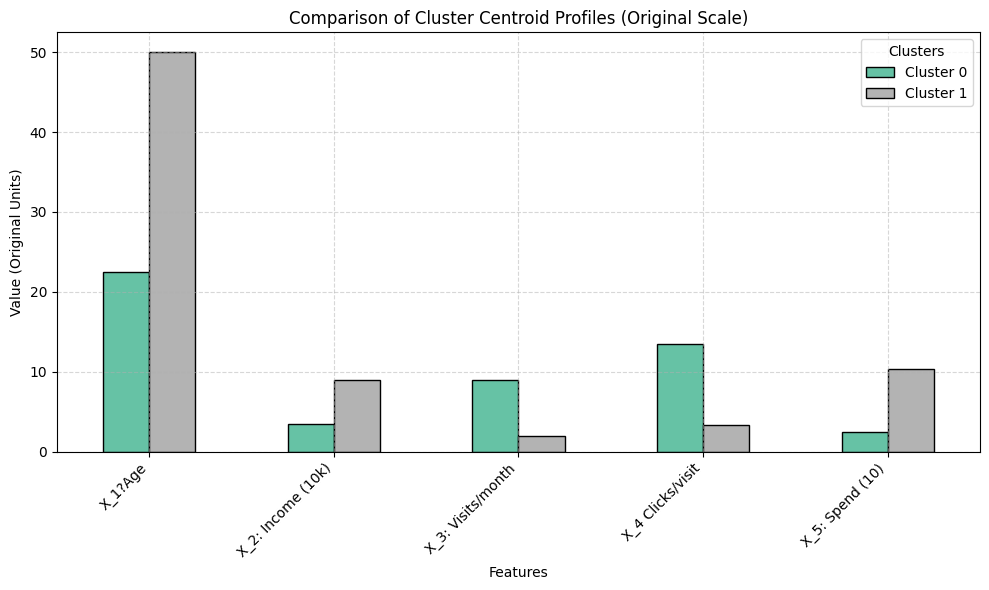

In [ ]:
# 1. Retrieve cluster centers
scaled_centroids = kmeans_optimal.cluster_centers_

# 2. Inverse-transform to original scale
unscaled_centroids = scaler.inverse_transform(scaled_centroids)

# 3. Create a DataFrame for readability
centroid_df = pd.DataFrame(
    unscaled_centroids,
    columns=numerical_features.columns,
    index=['Cluster 0', 'Cluster 1']
)

print("Cluster Centroids (Original Scale):")
display(centroid_df)

# 4. Plot a bar chart comparing features across clusters
plt.figure(figsize=(10, 6))
centroid_df.T.plot(kind='bar', figsize=(10, 6), colormap='Set2', edgecolor='black')
plt.title('Comparison of Cluster Centroid Profiles (Original Scale)')
plt.xlabel('Features')
plt.ylabel('Value (Original Units)')
plt.xticks(rotation=45, ha='right')
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(title='Clusters')
plt.tight_layout()
plt.show()

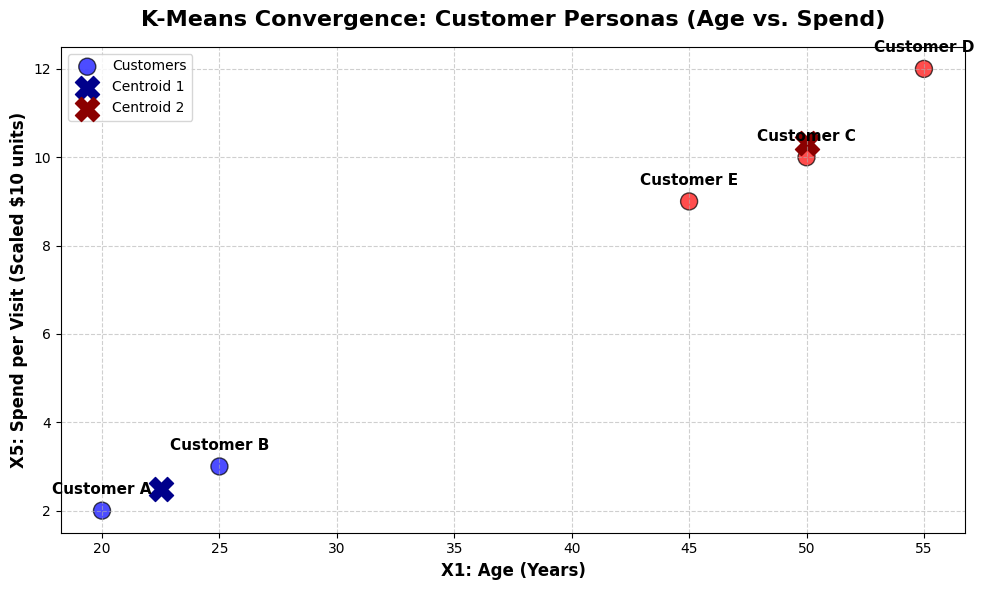

In [ ]:
import matplotlib.pyplot as plt

# 1. Customer Data (Extracting X1: Age and X5: Spend)
ages = [20, 25, 50, 55, 45]       # User A, B, C, D, E
spend = [2, 3, 10, 12, 9]         # User A, B, C, D, E
user_labels = ['A', 'B', 'C', 'D', 'E']

# Color coding based on our final manual assignments
# Cluster 1 (Blue) = A, B | Cluster 2 (Red) = C, D, E
point_colors = ['blue', 'blue', 'red', 'red', 'red']

# 2. Final Centroids Data (Extracting Age and Spend coordinates)
# C1 = (22.5, 2.5) | C2 = (50.0, 10.33)
centroid_ages = [22.5, 50.0]
centroid_spend = [2.5, 10.33]

# 3. Create the Figure
plt.figure(figsize=(10, 6))

# Plot the Customers
plt.scatter(ages, spend, color=point_colors, s=150, alpha=0.7, edgecolors='black', label='Customers')

# Annotate each customer point with their letter
for i, txt in enumerate(user_labels):
    plt.annotate(f'Customer {txt}', (ages[i], spend[i]),
                 textcoords="offset points", xytext=(0, 12), ha='center', fontsize=11, fontweight='bold')

# Plot the Final Centroids as large 'X' marks
plt.scatter(centroid_ages[centroid_spend.index(2.5)], 2.5, color='darkblue', marker='X', s=300, label='Centroid 1')
plt.scatter(centroid_ages[centroid_spend.index(10.33)], 10.33, color='darkred', marker='X', s=300, label='Centroid 2')

# 4. Formatting the Graph for the Textbook
plt.title('K-Means Convergence: Customer Personas (Age vs. Spend)', fontsize=16, fontweight='bold', pad=15)
plt.xlabel('X1: Age (Years)', fontsize=12, fontweight='bold')
plt.ylabel('X5: Spend per Visit (Scaled $10 units)', fontsize=12, fontweight='bold')

# Add a dashed grid for mathematical clarity
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(loc='upper left', fontsize=10)

# Display the figure
plt.tight_layout()
plt.show()

## Plot Cluster Centroids

### Subtask:
Extract the K-Means cluster centroids, inverse-transform them back to their original scale, and plot or print these profiles to summarize the customer segments.


## Final Task

### Subtask:
Provide a comprehensive final summary and analysis of the customer segments.


## Summary:

### Data Analysis Key Findings

* **Distinct Customer Segments Identified**: The K-Means clustering model successfully partitioned the customer base into two highly contrasting segments (Cluster 0 and Cluster 1).
* **Cluster 0 Profile (High-Engagement, Budget-Conscious)**:
  * **Demographics**: Younger average age (22.5 years) and a lower average annual income (\$35,000).
  * **Behavior**: Highly active digital users, averaging 9.0 monthly visits and 13.5 clicks per visit.
  * **Monetary Value**: Low average spending per transaction (\$25.00).
* **Cluster 1 Profile (Low-Engagement, Affluent Spenders)**:
  * **Demographics**: Older average age (50.0 years) with a significantly higher average annual income (\$90,000).
  * **Behavior**: Low digital activity, averaging only 2.0 monthly visits and approximately 3.3 clicks per visit.
  * **Monetary Value**: Highly profitable per transaction, with a high average spending of approximately \$103.30.

### Insights or Next Steps

* **Tailor Marketing Strategies per Segment**:
  * For **Cluster 0**, implement gamified loyalty programs, high-frequency engagement campaigns, and budget-friendly bundled offers to capitalize on their high digital activity.
  * For **Cluster 1**, focus on premium, high-value product recommendations and personalized VIP outreach (e.g., email or direct mail campaigns) that require minimal clicks and offer a seamless premium experience.
* **Optimize the Digital Funnel**: Investigate why Cluster 1 has extremely low engagement (visits and clicks). Simplifying the user interface or offering curated personal shopper experiences might increase their frequency of interaction without causing friction.


WCSS?

In [ ]:
import numpy as np
from sklearn.cluster import KMeans

# 1. Construct the Customer Dataset
# Columns: Age (X1), Income (X2), Visits (X3), Clicks (X4), Spend (X5)
X = np.array([
    [20, 3, 10, 15, 2],  # Customer A
    [25, 4, 8,  12, 3],  # Customer B
    [50, 9, 2,  3,  10], # Customer C
    [55, 10, 1, 2,  12], # Customer D
    [45, 8, 3,  5,  9]   # Customer E
])

# 2. Initialize and Fit the K-Means Model
# We set n_clusters=2 to match our manual exercise.
# n_init='auto' and random_state are used to ensure stable, reproducible results.
# To force the exact manual initialization we used (Customer A and C as centroids),
# we can explicitly pass init=np.array([X[0], X[2]]).
initial_centroids = np.array([X[0], X[2]])
kmeans_model = KMeans(n_clusters=2, init=initial_centroids, n_init=1)
kmeans_model.fit(X)

# 3. Extract the WCSS (Inertia)
wcss = kmeans_model.inertia_

# 4. Print the Results
print(f"Final Centroids:\n{kmeans_model.cluster_centers_}\n")
print(f"Cluster Assignments: {kmeans_model.labels_}")
print(f"Total WCSS (Inertia): {wcss:.2f}")

Final Centroids:
[[22.5         3.5         9.         13.5         2.5       ]
 [50.          9.          2.          3.33333333 10.33333333]]

Cluster Assignments: [0 0 1 1 1]
Total WCSS (Inertia): 83.33
